# Supplemental historical illustrations
Source: `scripts/figure.ipynb` in the preserved student-enroll folder. Original cells are unchanged.
**KNOWN-ISSUE[ISSUE-10]:** constraint directions differ between panels; partitions and residuals are hand constructed. These are not thesis Figures 4.1–4.2 or empirical coverage evidence. See `docs/findings.md`.


# RCC Method Visualization

This notebook demonstrates the Risk-Controlling Conformal (RCC) method through visualizations of the abstract mathematical formulation.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle, FancyBboxPatch
import pandas as pd
from scipy import stats

# Set random seed for reproducibility
np.random.seed(42)

# Setup plotting style
plt.style.use('default')

## 1. Synthetic Data Generation

We create base functions and conformalized bounds to illustrate RCC concepts:
- Base lower function: $q^{-}(x) = -0.5x^2 + 0.3x - 0.2$
- Base upper function: $q^{+}(x) = 0.4x^2 - 0.2x + 0.3$
- Conformalized lower bound: $\hat{C}_{lo}(x) = q^{-}(x) - \hat{q}$
- Conformalized upper bound: $\hat{C}_{hi}(x) = q^{+}(x) + \hat{q}$

In [21]:
# Define base functions
def q_lower(x):
    """Base lower function"""
    return -0.5 * x**2 + 0.3 * x - 0.2

def q_upper(x):
    """Base upper function"""
    return 0.4 * x**2 - 0.2 * x + 0.3

# Conformal adjustment
qhat = 0.25
alpha = 0.1  # Coverage level 1 - alpha = 0.9

# Generate evaluation points
x_vals = np.linspace(-1, 1, 500)
q_lower_vals = q_lower(x_vals)
q_upper_vals = q_upper(x_vals)

# Conformalized bounds (notation used in figures)
C_lo_vals = q_lower_vals - qhat
C_hi_vals = q_upper_vals + qhat

# Feasibility threshold
threshold = 0

## Figure 1: Conformal Bounds in Two Extreme Cases

This figure shows only the conformalized bounds:
- Lower bound: $\hat{C}_{lo}(x)$
- Upper bound: $\hat{C}_{hi}(x)$

The left panel shows a fully feasible case (upper bound below 0), and the right panel shows a fully infeasible case (lower bound above 0).

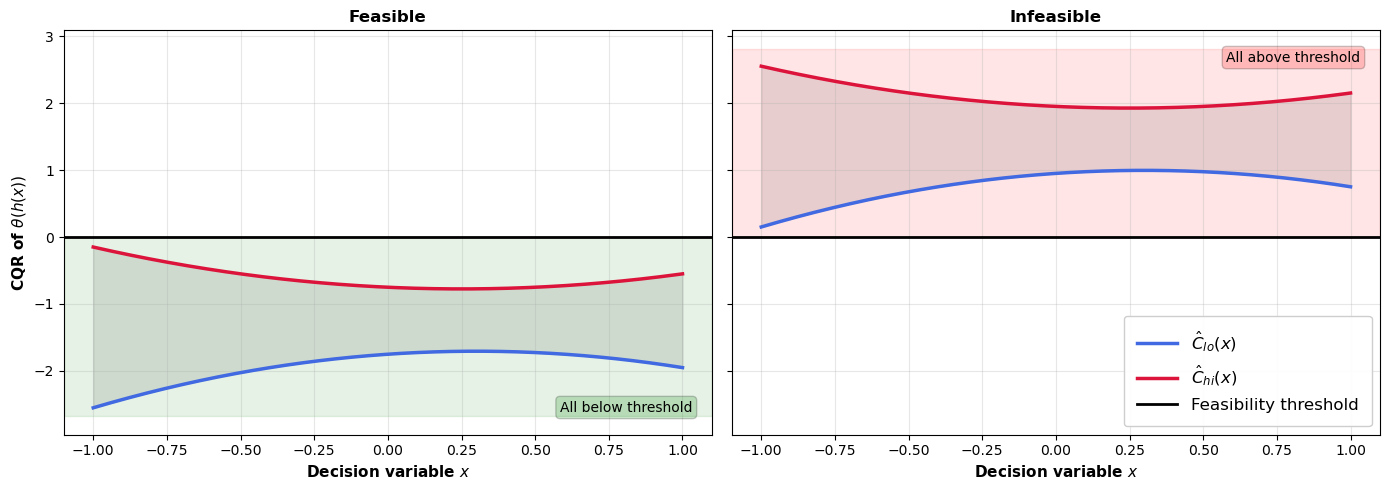

✓ Figure 1 updated: layout/logistics refined


In [28]:
# Figure 1: show only shifted quantiles in two extreme scenarios
lower_shifted_base = q_lower_vals - qhat
upper_shifted_base = q_upper_vals + qhat

# Offsets create two illustrative edge cases
feasible_offset = -1.3   # ensures max(upper) < 0
infeasible_offset = 1.4  # ensures min(lower) > 0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Left panel: fully feasible (even shifted upper < 0)
ax = axes[0]
lower_feasible = lower_shifted_base + feasible_offset
upper_feasible = upper_shifted_base + feasible_offset
ax.plot(x_vals, lower_feasible, color='royalblue', linewidth=2.5, label=r'$\hat{C}_{lo}(x)$')
ax.plot(x_vals, upper_feasible, color='crimson', linewidth=2.5, label=r'$\hat{C}_{hi}(x)$')
ax.fill_between(x_vals, lower_feasible, upper_feasible, alpha=0.2, color='gray')
ax.axhline(y=0, color='k', linestyle='-', linewidth=2, label='Feasibility threshold (0)')
ax.axhspan(ax.get_ylim()[0], 0, alpha=0.1, color='green')
ax.set_title('Feasible', fontsize=12, fontweight='bold')
ax.set_xlabel('Decision variable $x$', fontsize=11, fontweight='bold')
ax.set_ylabel(r'CQR of $\theta(h(x))$', fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.05, 'All below threshold', transform=ax.transAxes,
        fontsize=10, ha='right', va='bottom',
        bbox=dict(boxstyle='round', facecolor='green', alpha=0.2))

# Right panel: fully infeasible (shifted lower always > 0)
ax = axes[1]
lower_infeasible = lower_shifted_base + infeasible_offset
upper_infeasible = upper_shifted_base + infeasible_offset
ax.plot(x_vals, lower_infeasible, color='royalblue', linewidth=2.5, label=r'$\hat{C}_{lo}(x)$')
ax.plot(x_vals, upper_infeasible, color='crimson', linewidth=2.5, label=r'$\hat{C}_{hi}(x)$')
ax.fill_between(x_vals, lower_infeasible, upper_infeasible, alpha=0.2, color='gray')
ax.axhline(y=0, color='k', linestyle='-', linewidth=2, label='Feasibility threshold')
ax.axhspan(0, ax.get_ylim()[1], alpha=0.1, color='red')
ax.set_title('Infeasible', fontsize=12, fontweight='bold')
ax.set_xlabel('Decision variable $x$', fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.text(0.97, 0.95, 'All above threshold', transform=ax.transAxes,
        fontsize=10, ha='right', va='top',
        bbox=dict(boxstyle='round', facecolor='red', alpha=0.2))

# Legend in the empty lower-right area of the right subplot
ax.legend(loc='lower right', fontsize=12, framealpha=0.95, handlelength=2.4, borderpad=0.8, labelspacing=0.6)

plt.tight_layout()
plt.savefig('../results/rcc_fig1_quantiles.png', dpi=150, bbox_inches='tight')
plt.show()

print('✓ Figure 1 updated: layout/logistics refined')

## Figure 2: Feasibility Classification Regions

This figure demonstrates the RCC partitioning logic across four iterations:
- **Green zones**: feasible regions where the upper bound is already below 0
- **Red zones**: infeasible regions where the lower bound is already above 0
- **White zones**: undetermined regions that still need splitting or checking

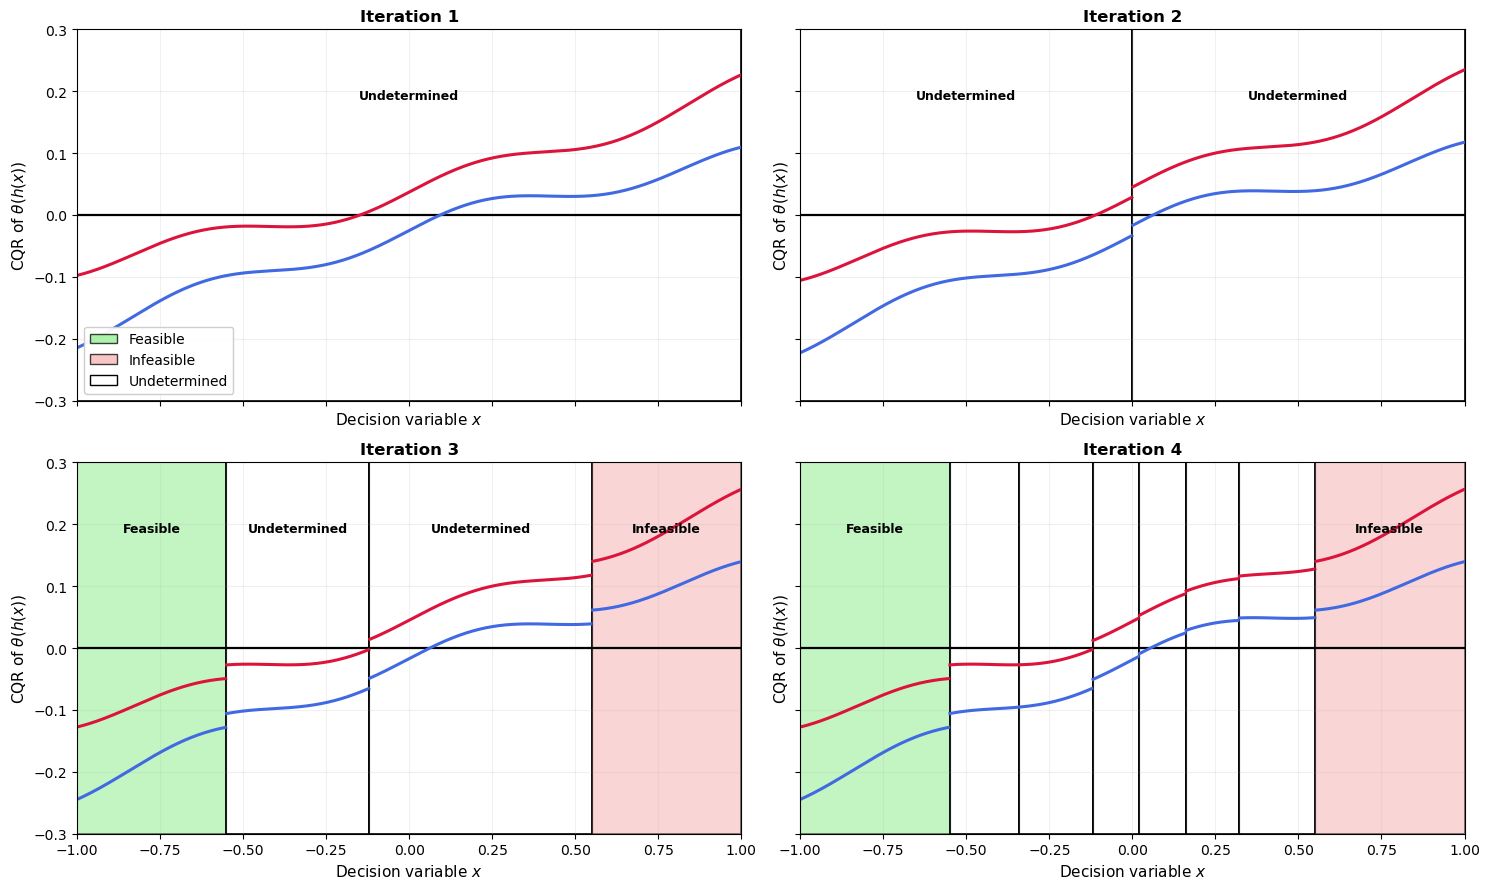

✓ Figure 2 updated: 4 iterations in a 2x2 layout
  Iteration 1: undetermined
  Iteration 2: two shifted undetermined halves
  Iteration 3: leftmost feasible, rightmost infeasible
  Iteration 4: only middle regions split further


In [41]:
# Figure 2: four-iteration recursive partitioning with 2x2 layout
# The curves trend upward and the vertical gap is wider on the sides, narrower in the middle.
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
axes = axes.ravel()

x_fig2 = np.linspace(-1, 1, 600)
# Shared trend with a gentle non-monotonic wiggle.
center_curve = 0.145 * x_fig2 + 0.018 * np.sin(2.4 * np.pi * x_fig2) + 0.006
# U-shaped gap: narrower near x=0 and wider toward both ends.
gap_curve = 0.062 + 0.055 * x_fig2**2
base_C_lo = center_curve - 0.5 * gap_curve
base_C_hi = center_curve + 0.5 * gap_curve


def bounds_with_offset(offset):
    return base_C_lo + offset, base_C_hi + offset


def draw_region(ax, x_left, x_right, offset, fill_color, boundary=False):
    mask = (x_fig2 >= x_left) & (x_fig2 <= x_right)
    x_seg = x_fig2[mask]
    C_lo_seg, C_hi_seg = bounds_with_offset(offset)
    C_lo_seg = C_lo_seg[mask]
    C_hi_seg = C_hi_seg[mask]

    ax.axvspan(
        x_left,
        x_right,
        facecolor=fill_color,
        edgecolor='black',
        alpha=0.55 if fill_color != 'white' else 1.0,
        linewidth=1.2,
    )
    ax.plot(x_seg, C_lo_seg, color='royalblue', linewidth=2.2)
    ax.plot(x_seg, C_hi_seg, color='crimson', linewidth=2.2)
    if boundary:
        ax.axvline(x_right, color='black', alpha=0.25, linewidth=1)


iteration_data = [
    [(-1.0, 1.0, 0.000, 'mixed')],
    [(-1.0, 0.0, -0.008, 'mixed'), (0.0, 1.0, 0.008, 'mixed')],
    [(-1.0, -0.55, -0.030, 'feasible'), (-0.55, -0.12, -0.008, 'mixed'), (-0.12, 0.55, 0.008, 'mixed'), (0.55, 1.0, 0.030, 'infeasible')],
    [(-1.0, -0.55, -0.030, 'feasible'),
     (-0.55, -0.34, -0.008, 'mixed'), (-0.34, -0.12, -0.008, 'mixed'),
     (-0.12, 0.02, 0.006, 'mixed'), (0.02, 0.16, 0.010, 'mixed'), (0.16, 0.32, 0.014, 'mixed'), (0.32, 0.55, 0.018, 'mixed'),
     (0.55, 1.0, 0.030, 'infeasible')],
]

panel_titles = ['Iteration 1', 'Iteration 2', 'Iteration 3', 'Iteration 4']
fill_colors = {
    'feasible': 'lightgreen',
    'infeasible': '#f6b3b3',
    'mixed': 'white',
}

for idx, ax in enumerate(axes):
    regions = iteration_data[idx]

    ax.axhline(0, color='black', linewidth=1.6)
    for region_idx, (x_left, x_right, offset, status) in enumerate(regions):
        draw_region(ax, x_left, x_right, offset, fill_colors[status], boundary=(region_idx < len(regions) - 1))

        if idx < 3:
            label = 'Undetermined' if status == 'mixed' else ('Feasible' if status == 'feasible' else 'Infeasible')
            ax.text(
                (x_left + x_right) / 2,
                0.84,
                label,
                transform=ax.get_xaxis_transform(),
                ha='center',
                va='top',
                fontsize=9,
                fontweight='bold',
            )
        elif status in ('feasible', 'infeasible'):
            label = 'Feasible' if status == 'feasible' else 'Infeasible'
            ax.text(
                (x_left + x_right) / 2,
                0.84,
                label,
                transform=ax.get_xaxis_transform(),
                ha='center',
                va='top',
                fontsize=9,
                fontweight='bold',
            )

    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.30, 0.30)
    ax.set_title(panel_titles[idx], fontsize=12, fontweight='bold')
    ax.set_xlabel('Decision variable $x$', fontsize=11)
    ax.set_ylabel(r'CQR of $\theta(h(x))$', fontsize=11)
    ax.grid(True, alpha=0.18)

# Legend only once
legend_handles = [
    mpatches.Patch(facecolor='lightgreen', edgecolor='black', alpha=0.75, label='Feasible'),
    mpatches.Patch(facecolor='#f6b3b3', edgecolor='black', alpha=0.75, label='Infeasible'),
    mpatches.Patch(facecolor='white', edgecolor='black', label='Undetermined'),
]
axes[0].legend(handles=legend_handles, loc='lower left', fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.savefig('../results/rcc_fig2_partitioning.png', dpi=150, bbox_inches='tight')
plt.show()

print('✓ Figure 2 updated: 4 iterations in a 2x2 layout')
print('  Iteration 1: undetermined')
print('  Iteration 2: two shifted undetermined halves')
print('  Iteration 3: leftmost feasible, rightmost infeasible')
print('  Iteration 4: only middle regions split further')

## Figure 3: Algorithm Decision Logic Summary

A simplified view showing the key checks and decision paths in RCC:

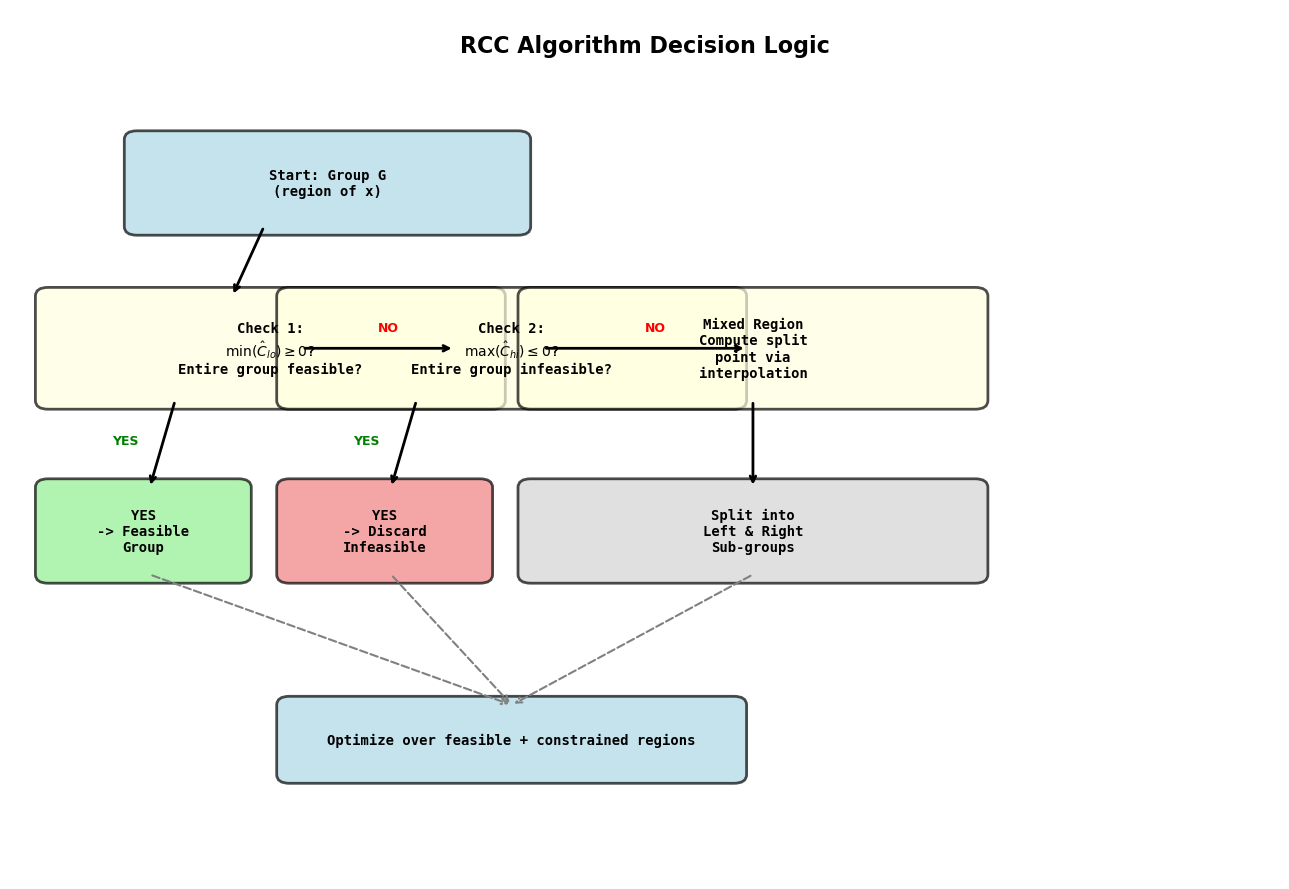

✓ Figure 3 saved: RCC algorithm decision logic flowchart


In [23]:
fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Title
ax.text(5, 9.5, 'RCC Algorithm Decision Logic', fontsize=16, fontweight='bold', ha='center')

# Define box positions and content
boxes = [
    # (x, y, width, height, text, color)
    (1, 7.5, 3, 1, 'Start: Group G\n(region of x)', 'lightblue'),

    # First check with C_lo
    (0.3, 5.5, 3.5, 1.2,
     'Check 1:\n$\\min(\\hat{C}_{lo}) \\geq 0$?\nEntire group feasible?',
     'lightyellow'),

    # YES: add to opt
    (0.3, 3.5, 1.5, 1, 'YES\n-> Feasible\nGroup', 'lightgreen'),

    # NO: check second condition with C_hi
    (2.2, 5.5, 3.5, 1.2,
     'Check 2:\n$\\max(\\hat{C}_{hi}) \\leq 0$?\nEntire group infeasible?',
     'lightyellow'),

    # YES: discard
    (2.2, 3.5, 1.5, 1, 'YES\n-> Discard\nInfeasible', 'lightcoral'),

    # NO: split
    (4.1, 5.5, 3.5, 1.2,
     'Mixed Region\nCompute split\npoint via\ninterpolation',
     'lightyellow'),

    # Split result
    (4.1, 3.5, 3.5, 1, 'Split into\nLeft & Right\nSub-groups', 'lightgray'),

    # Finalize
    (2.2, 1.2, 3.5, 0.8,
     'Optimize over feasible + constrained regions',
     'lightblue'),
]

# Draw boxes
for x, y, w, h, text, color in boxes:
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1',
                         edgecolor='black', facecolor=color, linewidth=2, alpha=0.7)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h / 2, text, fontsize=10, ha='center', va='center',
            fontweight='bold', family='monospace')

# Draw arrows
arrow_props = dict(arrowstyle='->', lw=2, color='black')
# From start to check 1
ax.annotate('', xy=(1.75, 6.7), xytext=(2, 7.5), arrowprops=arrow_props)

# From check 1: YES to feasible
ax.annotate('', xy=(1.1, 4.5), xytext=(1.3, 5.5), arrowprops=arrow_props)
ax.text(0.8, 5, 'YES', fontsize=9, fontweight='bold', color='green')

# From check 1: NO to check 2
ax.annotate('', xy=(3.5, 6.1), xytext=(2.3, 6.1), arrowprops=arrow_props)
ax.text(2.9, 6.3, 'NO', fontsize=9, fontweight='bold', color='red')

# From check 2: YES to discard
ax.annotate('', xy=(3.0, 4.5), xytext=(3.2, 5.5), arrowprops=arrow_props)
ax.text(2.7, 5, 'YES', fontsize=9, fontweight='bold', color='green')

# From check 2: NO to split
ax.annotate('', xy=(5.8, 6.1), xytext=(4.2, 6.1), arrowprops=arrow_props)
ax.text(5, 6.3, 'NO', fontsize=9, fontweight='bold', color='red')

# From split to result
ax.annotate('', xy=(5.85, 4.5), xytext=(5.85, 5.5), arrowprops=arrow_props)

# From all paths to finalize
ax.annotate('', xy=(3.95, 2), xytext=(1.1, 3.5),
            arrowprops=dict(arrowstyle='->', lw=1.5, color='gray', linestyle='dashed'))
ax.annotate('', xy=(3.95, 2), xytext=(3, 3.5),
            arrowprops=dict(arrowstyle='->', lw=1.5, color='gray', linestyle='dashed'))
ax.annotate('', xy=(3.95, 2), xytext=(5.85, 3.5),
            arrowprops=dict(arrowstyle='->', lw=1.5, color='gray', linestyle='dashed'))

plt.tight_layout()
plt.savefig('../results/rcc_fig3_algorithm_logic.png', dpi=150, bbox_inches='tight')
plt.show()

print('✓ Figure 3 saved: RCC algorithm decision logic flowchart')

## Figure 4: Calibration Residuals and Conformal Bounds

This figure shows how the conformal bounds $\hat{C}_{lo}(x)$ and $\hat{C}_{hi}(x)$ are constructed to guarantee coverage at level $1-\alpha$.

Residuals measure how far each calibration point lies outside the interval $[\hat{C}_{lo}(x),\hat{C}_{hi}(x)]$.

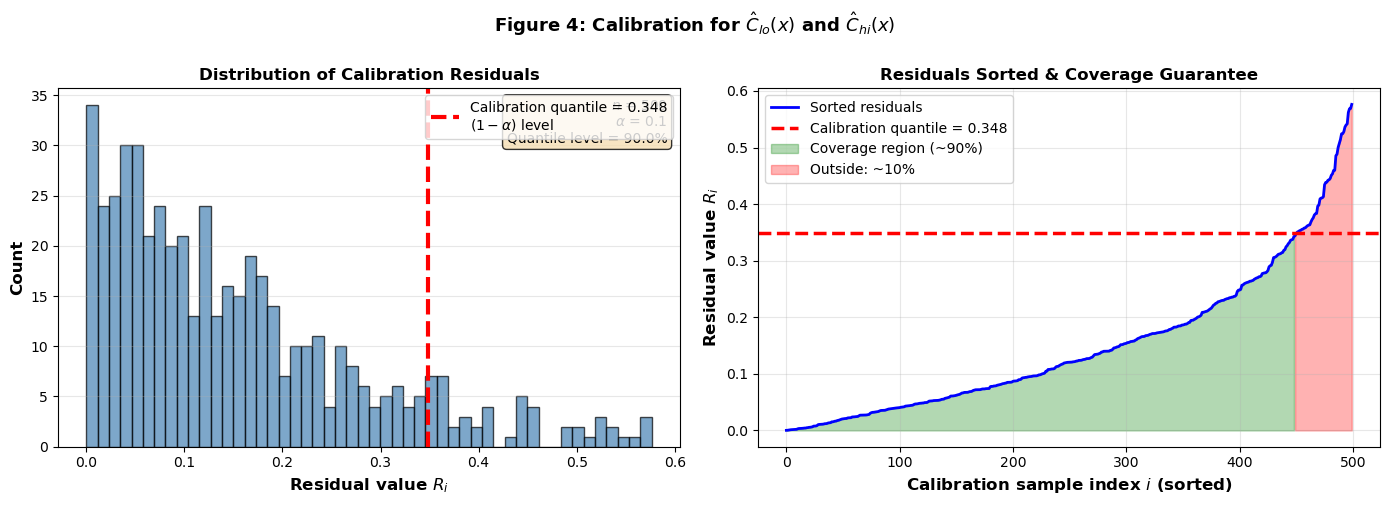

✓ Figure 4 saved: calibration for conformal bounds
  Residuals computed from 500 calibration samples
  Calibration quantile: 0.3481 (at 90.0% quantile)
  Guarantee: P(y in [C_lo(x), C_hi(x)]) >= 90.0%


In [24]:
# Generate synthetic calibration residuals
# Residuals represent distance outside [C_lo, C_hi]
n_cal = 500
np.random.seed(42)

# Synthetic residuals: mostly small, with a tail representing out-of-interval samples
residuals_cal = np.concatenate([
    np.abs(np.random.normal(-0.05, 0.15, n_cal - 50)),  # Most calibration points
    np.random.uniform(0.3, 0.6, 50)  # Outliers
])
residuals_cal = residuals_cal[residuals_cal >= 0]  # Ensure non-negative

# Sort residuals
residuals_sorted = np.sort(residuals_cal)

# Compute calibration quantile used to form C_lo/C_hi
quantile_idx = int(np.ceil((1 - alpha) * (len(residuals_sorted) + 1))) - 1
quantile_idx = max(0, min(quantile_idx, len(residuals_sorted) - 1))
qhat_computed = residuals_sorted[quantile_idx]

# Create figure with 2 subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram of residuals
ax1.hist(residuals_sorted, bins=50, color='steelblue', alpha=0.7, edgecolor='black', linewidth=1)
ax1.axvline(qhat_computed, color='red', linestyle='--', linewidth=3,
            label=f'Calibration quantile = {qhat_computed:.3f}\n$(1-\\alpha)$ level')

ax1.set_xlabel('Residual value $R_i$', fontsize=12, fontweight='bold')
ax1.set_ylabel('Count', fontsize=12, fontweight='bold')
ax1.set_title('Distribution of Calibration Residuals', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10, loc='upper right')
ax1.grid(True, alpha=0.3, axis='y')

# Add text annotation
ax1.text(0.98, 0.97, f'$n$ = {len(residuals_sorted)}\n$\\alpha$ = {alpha}\nQuantile level = {1-alpha:.1%}',
         transform=ax1.transAxes, fontsize=10, verticalalignment='top', horizontalalignment='right',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Right: Sorted residuals with coverage region
indices = np.arange(len(residuals_sorted))
ax2.plot(indices, residuals_sorted, 'b-', linewidth=2, label='Sorted residuals')
ax2.axhline(qhat_computed, color='red', linestyle='--', linewidth=2.5,
            label=f'Calibration quantile = {qhat_computed:.3f}')

# Shade coverage region
coverage_idx = max(0, int((1 - alpha) * len(residuals_sorted)) - 1)
ax2.fill_between(indices[:coverage_idx], 0, residuals_sorted[:coverage_idx],
                 alpha=0.3, color='green', label=f'Coverage region (~{1-alpha:.0%})')
ax2.fill_between(indices[coverage_idx:], 0, residuals_sorted[coverage_idx:],
                 alpha=0.3, color='red', label=f'Outside: ~{alpha:.0%}')

ax2.set_xlabel('Calibration sample index $i$ (sorted)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Residual value $R_i$', fontsize=12, fontweight='bold')
ax2.set_title('Residuals Sorted & Coverage Guarantee', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10, loc='upper left')
ax2.grid(True, alpha=0.3)

fig.suptitle('Figure 4: Calibration for $\\hat{C}_{lo}(x)$ and $\\hat{C}_{hi}(x)$',
             fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.savefig('../results/rcc_fig4_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

print('✓ Figure 4 saved: calibration for conformal bounds')
print(f'  Residuals computed from {len(residuals_sorted)} calibration samples')
print(f'  Calibration quantile: {qhat_computed:.4f} (at {100 * (1 - alpha):.1f}% quantile)')
print(f'  Guarantee: P(y in [C_lo(x), C_hi(x)]) >= {1 - alpha:.1%}')

## Summary: How RCC Works

**The Risk-Controlling Conformal (RCC) method** provides a principled approach to optimize under uncertainty while maintaining feasibility guarantees. Here's the complete picture:

### 1. **Foundation: Conformal Bounds**
   - RCC uses conformalized bounds $[\hat{C}_{lo}(x), \hat{C}_{hi}(x)]$
   - These bounds are calibrated to guarantee $(1-\alpha)$ coverage
   - Figure 1 shows this relationship

### 2. **Key Insight: Partition the Decision Space**
   - Instead of checking the model everywhere, RCC partitions regions into categories:
     - **Green (Feasible)**: Minimum lower bound already satisfies the constraint
     - **Red (Infeasible)**: Maximum upper bound still violates the constraint
     - **Yellow (Mixed)**: Needs either further splitting or explicit constraint checking
   - Figure 2 shows this partitioning process over iterations

### 3. **Algorithm: Recursive Splitting**
   - Start with the entire decision space
   - Test each region: fully feasible, fully infeasible, or mixed
   - If mixed, compute a split point and recurse on sub-regions
   - Figure 3 shows the decision logic

### 4. **Theoretical Guarantee: Conformal Coverage**
   - Bounds are calibrated on held-out data
   - Ensures: $P(y \in [\hat{C}_{lo}(x), \hat{C}_{hi}(x)]) \geq 1-\alpha$
   - Figure 4 shows how this guarantee is achieved

### Key Advantages:
✓ **Avoids expensive model checks** in large feasible/infeasible regions  
✓ **Maintains statistical guarantees** on coverage and feasibility  
✓ **Scales well** via adaptive partitioning  
✓ **Works with any learned model family**